# CAREMap · 06 Feasibility: could an Ouray-style project work here?

v2, step 3. The need score says where childcare and housing shortages overlap. It says nothing about whether the Ouray model would *work* there. This notebook adds a separate **fit layer** for High and Medium counties, built from what the Ouray project actually needed. Fit never changes the need score or the tiers.

## What Waterview needed (from public reporting)

| What the project relied on | Source |
|---|---|
| Two homes built to state family-childcare licensing rules from the start (fencing, square footage, fire-egress ramps), inside a 19-home first phase | KUNC (Feb 2026); Ouray County Plaindealer (Nov 2024) |
| Licenses that let each home grow from 4-6 children to 12 | Ouray County Plaindealer (Nov 2024); KUNC |
| A long-term owner: Mission Driven Finance bought both homes ($479,000 each) and rents them below market, rising toward 100% of AMI, with an option to buy | Ouray County Plaindealer; KUNC |
| An early childhood council (Bright Futures) to recruit, train (All Our Kin business curriculum) and support providers; only 2 of 6 recruits could relocate | Ouray County Plaindealer |
| Documented local need: 2022 county survey, 158 children under 5 and 55 slots | Ouray County Plaindealer |
| About $10M in blended funding: grants, low-cost construction loans, Colorado's Prop 123 housing fund; $8M+ in state grants and loans | KUNC; Ouray County Plaindealer (Mar 2023) |
| Rural Homes' cost model: donated land, factory-built modular homes, low-cost financing, down-payment help | Telluride Foundation; Penn Center for Social Impact; Colorado Sun |
| For-sale homes priced $275,000 to $480,000 for local workers | Ouray County Plaindealer (Mar 2023) |
| Local government approval (Ouray planning commission) | Ouray County Plaindealer (Mar 2023) |

Some of these can be measured for every county. Others can only be checked locally. The framework keeps the two apart.

## The framework

**Measured for every county (scored, 0-4):**

| # | Criterion | Why it matters at Waterview | Test |
|---|---|---|---|
| F1 | Population holding or growing | Homes have to sell, and enrollment was slow at first | Population change 2020-2025 above -2% |
| F2 | Market prices above the model's price point | Rural Homes sells new homes at $275k-$480k; that only helps where it is below the local market | Median home value ≥ $275,000 |
| F3 | A local pool of home-based providers | Recruiting was the bottleneck (2 of 6 could relocate) | Census self-employed childcare businesses per 1,000 children under 5 above the bottom quarter of the county's metro/rural group |
| F4 | State licenses group/large family homes | Both providers planned to grow to 12 children, which is what makes a home program pay | State is not on the 2017 federal list of 13 states without a separate group-home license (*see note*) |

**Needs local research (not scored):** land that can be donated or bought cheaply; zoning and local approval for home childcare in a new subdivision; state or local housing money (like Prop 123); a long-term owner such as a CDFI; an early-childhood organization to recruit and train providers; a modular builder within shipping range; a local survey confirming demand.

**Fit:** Strong = all 4 met, Possible = 3, Weak = 0-2.

**Tested and dropped: a tight rental market** (rental vacancy ≤ 5%). It seemed obvious, but it fails the place the model came from: the Census shows Ouray County at 19% rental vacancy, even though local reporting describes an acute shortage. Archuleta and Maui show 17-18%. In resort counties, the Census vacancy count appears to pick up units held for short-term or seasonal renting, so it measures the wrong thing exactly where this model is most likely to be used. It is still reported below, but it is not scored. Fit is only shown for High and Medium counties.

*Note on F4.* The source is the ECQA Center's *Trends in Group Child Care Home Licensing Requirements and Policies for 2017* (HHS/ACF, 2020). Some of the 13 states let a single family-home license go above 6 children (for example, Washington and Virginia allow up to 12), so F4 = "No" means *check the state's rules*, not "impossible". The data is from 2017.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

s = pd.read_csv(ROOT / "data/processed/county_scores_v1.csv", dtype={"GEOID": str})
s["high_if_zero"] = s["high_if_zero"].astype(str).eq("True")
acs = pd.read_csv(ROOT / "data/raw/acs_2020_2024.csv", dtype={"GEOID": str})
join = pd.read_csv(ROOT / "data/processed/county_v1_join.csv", dtype={"GEOID": str})
d = (s[s["tier"] != "Not scored"]
     .merge(acs[["GEOID", "median_home_value"]], on="GEOID", how="left")
     .merge(join[["GEOID", "nes_estab"]], on="GEOID", how="left"))
d["nes_per_1k_kids"] = d["nes_estab"] / d["kids_under5"] * 1000

NO_GROUP_HOME_LICENSE_2017 = {"AR", "GA", "KY", "LA", "ME", "MA", "NJ", "NC", "SD", "VT", "VA", "WA", "WI"}
PRICE_POINT = 275_000

d["F1_population"] = d["pop_change_pct"] > -2
d["F2_price_above_model"] = d["median_home_value"] >= PRICE_POINT
d["tight_rentals_not_scored"] = d["rental_vacancy_rate"] <= 0.05
d["F3_provider_pool"] = d["nes_per_1k_kids"] > d.groupby("group")["nes_per_1k_kids"].transform(lambda x: x.quantile(0.25))
d["F4_group_home_license"] = ~d["USPS"].isin(NO_GROUP_HOME_LICENSE_2017)
crit = ["F1_population", "F2_price_above_model", "F3_provider_pool", "F4_group_home_license"]
d["fit_points"] = d[crit].sum(axis=1)
d["fit"] = np.select([d["fit_points"] == 4, d["fit_points"] == 3], ["Strong", "Possible"], "Weak")
d.loc[~d["tier"].isin(["High", "Medium"]), "fit"] = ""

hm = d[d["tier"].isin(["High", "Medium"])]
print(f"High and Medium counties: {len(hm)}")
print(f"Share meeting the dropped rental test (not scored): {hm['tight_rentals_not_scored'].mean():.2f}")
hm[crit].mean().round(2).rename("share meeting").to_frame()

High and Medium counties: 760
Share meeting the dropped rental test (not scored): 0.51


,share meeting
F1_population,0.84
F2_price_above_model,0.38
F3_provider_pool,0.61
F4_group_home_license,0.71


## Check: does the framework pass Ouray County itself?

Ouray County is not in the need ranking (it has fewer than 100 children under 5 in the Census estimate), but the fit criteria can still be computed for it. A framework built from Waterview should rate Waterview's own county well.

In [2]:
o = (s[s["GEOID"] == "08091"].merge(acs[["GEOID", "median_home_value"]], on="GEOID").merge(join[["GEOID", "nes_estab"]], on="GEOID"))
o["nes_per_1k_kids"] = o["nes_estab"] / o["kids_under5"] * 1000
grp_q25 = d[d["group"] == "Nonmetro"]["nes_per_1k_kids"].quantile(0.25)
check = pd.Series({
    "children under 5": int(o["kids_under5"].iloc[0]),
    "F1 population change (%)": round(o["pop_change_pct"].iloc[0], 1),
    "F2 median home value": int(o["median_home_value"].iloc[0]),
    "F3 self-employed providers per 1,000 kids": round(o["nes_per_1k_kids"].iloc[0], 1),
    "F4 state licenses group homes": "CO" not in NO_GROUP_HOME_LICENSE_2017,
    "dropped: rental vacancy": f"{o['rental_vacancy_rate'].iloc[0]:.0%}",
})
passes = [o["pop_change_pct"].iloc[0] > -2, o["median_home_value"].iloc[0] >= PRICE_POINT,
          o["nes_per_1k_kids"].iloc[0] > grp_q25, "CO" not in NO_GROUP_HOME_LICENSE_2017]
print(check.to_string())
print(f"\nOuray County meets {sum(passes)} of 4 scored criteria")

children under 5                                 94
F1 population change (%)                        7.9
F2 median home value                         739800
F3 self-employed providers per 1,000 kids     106.4
F4 state licenses group homes                  True
dropped: rental vacancy                         19%

Ouray County meets 4 of 4 scored criteria


## How fit lines up with need

In [3]:
hm = d[d["tier"].isin(["High", "Medium"])].copy()
hm["tier_label"] = np.where(hm["tier"] == "Medium", "Medium",
                            np.where(hm["high_if_zero"], "High, unconfirmed", "High"))
tab = pd.crosstab(hm["tier_label"], hm["fit"]).reindex(columns=["Strong", "Possible", "Weak"]).fillna(0).astype(int)
tab["total"] = tab.sum(axis=1)
display(tab)
print(pd.crosstab(hm["group"], hm["fit"], normalize="index").reindex(columns=["Strong", "Possible", "Weak"]).round(2))

fit,Strong,Possible,Weak,total
tier_label,,,,
High,5,29,29,63
"High, unconfirmed",4,12,27,43
Medium,110,247,297,654


fit       Strong  Possible  Weak
group                           
Metro       0.31      0.36  0.33
Nonmetro    0.06      0.39  0.55


### Is fit just need in disguise?

If fit were simply the housing side of the need score again, it would add nothing. Check how fit points relate to the two need scores among High and Medium counties.

In [4]:
for col in ["childcare_score", "housing_score", "combined_score"]:
    print(f"Rank correlation, fit points vs {col}: {hm['fit_points'].rank().corr(hm[col].rank()):.2f}")
print("\nWhich criteria pull in which direction (High+Medium counties):")
rows = []
for c in crit:
    rows.append({"criterion": c,
                 "corr with childcare score": round(hm[c].astype(float).rank().corr(hm["childcare_score"].rank()), 2),
                 "corr with housing score": round(hm[c].astype(float).rank().corr(hm["housing_score"].rank()), 2)})
pd.DataFrame(rows)

Rank correlation, fit points vs childcare_score: -0.34
Rank correlation, fit points vs housing_score: 0.25
Rank correlation, fit points vs combined_score: -0.06

Which criteria pull in which direction (High+Medium counties):


,criterion,corr with childcare score,corr with housing score
0,F1_population,-0.13,0.05
1,F2_price_above_model,-0.23,0.31
2,F3_provider_pool,-0.35,0.15
3,F4_group_home_license,0.01,-0.01


### How much does the $275k price point matter?

In [5]:
rows = []
for p in [225_000, 275_000, 350_000]:
    pts = d[crit].sum(axis=1) - d["F2_price_above_model"] + (d["median_home_value"] >= p)
    f = np.select([pts == 4, pts == 3], ["Strong", "Possible"], "Weak")[d["tier"].isin(["High", "Medium"]).values]
    rows.append({"price point": f"${p:,}", "Strong": (f == "Strong").sum(), "Possible": (f == "Possible").sum(), "Weak": (f == "Weak").sum()})
pd.DataFrame(rows)

,price point,Strong,Possible,Weak
0,"$225,000",155,297,308
1,"$275,000",119,288,353
2,"$350,000",70,287,403


## The shortlist: High need and Strong fit

In [6]:
cols = ["county_name", "USPS", "group", "rank_in_group", "tier", "high_if_zero", "fit_points", "median_home_value",
        "pop_change_pct", "nes_per_1k_kids", "rental_vacancy_rate"] + crit
short = hm[(hm["tier"] == "High") & (hm["fit"] == "Strong")].sort_values(["group", "rank_in_group"])
print(f"High need + Strong fit: {len(short)} counties ({(~short['high_if_zero']).sum()} confirmed High)")
short[cols].round(3)

High need + Strong fit: 9 counties (5 confirmed High)


,county_name,USPS,group,rank_in_group,tier,high_if_zero,fit_points,median_home_value,pop_change_pct,nes_per_1k_kids,rental_vacancy_rate,F1_population,F2_price_above_model,F3_provider_pool,F4_group_home_license
205,Monterey County,CA,Metro,5.0,High,False,4,781000.0,-1.536,23.740,0.021,True,True,True,True
1570,Broadwater County,MT,Metro,7.0,High,True,4,426600.0,23.805,22.222,0.080,True,True,True,True
1698,Storey County,NV,Metro,17.0,High,True,4,426400.0,3.700,46.875,0.169,True,True,True,True
2267,Jasper County,SC,Metro,19.0,High,False,4,325500.0,32.152,23.309,0.027,True,True,True,True
213,San Benito County,CA,Metro,20.0,High,False,4,793400.0,8.612,34.539,0.011,True,True,True,True
2558,Johnson County,TX,Metro,27.0,High,False,4,285900.0,20.498,18.095,0.071,True,True,True,True
2686,Kane County,UT,Nonmetro,16.0,High,True,4,410900.0,11.693,20.566,0.159,True,True,True,True
1696,Nye County,NV,Nonmetro,55.0,High,False,4,290900.0,10.291,24.966,0.081,True,True,True,True
558,Lemhi County,ID,Nonmetro,78.0,High,True,4,326100.0,6.524,27.027,0.018,True,True,True,True


In [7]:
print("Case-study counties:")
case = d[(d["GEOID"].isin(["15009", "08007", "26085"]))]
case[cols[:-4] + ["fit"] + crit].T

Case-study counties:


,239,530,1243
county_name,Archuleta County,Maui County,Lake County
USPS,CO,HI,MI
group,Nonmetro,Metro,Nonmetro
rank_in_group,3.0,2.0,56.0
tier,High,High,Medium
high_if_zero,False,False,False
fit_points,3,2,2
median_home_value,478100.0,904700.0,133900.0
pop_change_pct,6.554447,-2.530923,9.068344
nes_per_1k_kids,15.09434,12.923705,12.048193


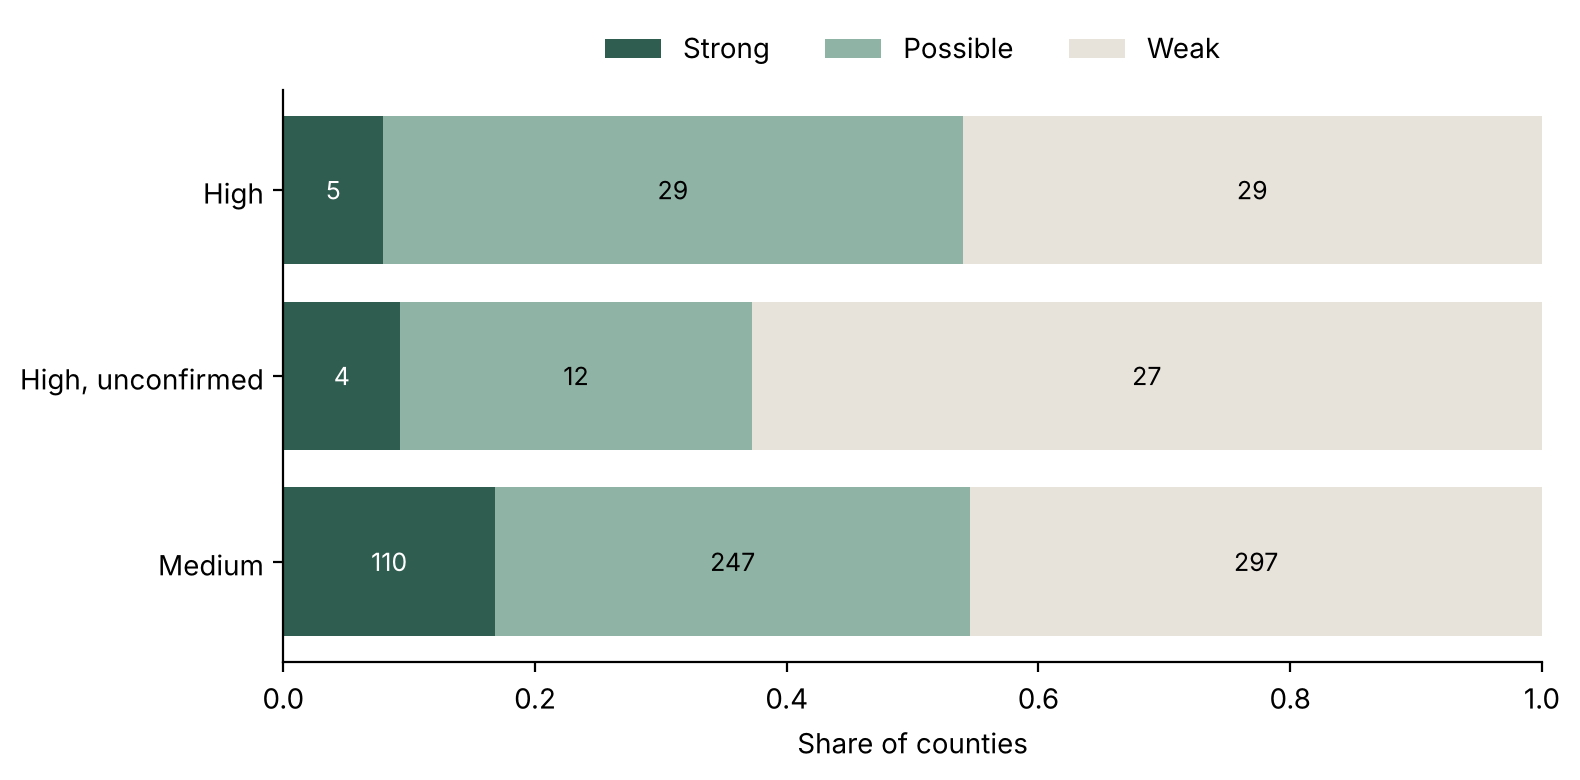

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
order = ["High", "High, unconfirmed", "Medium"]
cnt = tab.loc[[o for o in order if o in tab.index], ["Strong", "Possible", "Weak"]]
share = cnt.div(cnt.sum(axis=1), axis=0)
left = np.zeros(len(share))
for col, c in zip(["Strong", "Possible", "Weak"], ["#2F5D50", "#8FB3A5", "#E7E2DA"]):
    ax.barh(share.index, share[col], left=left, color=c, label=col)
    for i, (v, n) in enumerate(zip(share[col], cnt[col])):
        if v > 0.06:
            ax.text(left[i] + v / 2, i, str(n), ha="center", va="center", fontsize=9, color="white" if col == "Strong" else "black")
    left += share[col].values
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("Share of counties"); ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIG / "06_fit_by_tier.png", dpi=150); plt.show()

In [9]:
out = d[["GEOID", "USPS", "county_name", "group", "tier", "high_if_zero", "median_home_value", "rental_vacancy_rate",
          "pop_change_pct", "nes_per_1k_kids", "tight_rentals_not_scored"] + crit + ["fit_points", "fit"]]
out.to_csv(ROOT / "data/processed/county_fit.csv", index=False)
print("Saved data/processed/county_fit.csv")

Saved data/processed/county_fit.csv


## What this means

**The framework passes its own test.** Ouray County meets all 4 scored criteria. The rental-vacancy test was dropped because it failed Ouray, which reads as a measurement problem in resort counties rather than a real signal.

**Fit is a separate question from need.** Among High and Medium counties, fit points barely track the combined need score (-0.06). Showing fit as a separate layer adds information instead of repeating the ranking.

**But fit and childcare need pull against each other.** Counties with the worst childcare shortages tend to have the thinnest pools of home-based providers (-0.35 with F3) and lower home prices (-0.23 with F2). Where care is scarcest, there are also the fewest people already doing it. In Ouray, the early-childhood council's recruiting and training was the part that made the homes usable. In the highest-need counties, that partner is likely the hardest piece to replace, more than the housing.

**Few High counties are an easy fit.** 9 of 106 High counties meet all four criteria (5 of them confirmed High), 41 meet three, and 56 meet two or fewer. Strong fit is mostly growing metro-edge counties in the West and South: Monterey and San Benito CA, Jasper SC, Johnson TX, Broadwater MT, Storey and Nye NV, Kane UT, Lemhi ID. Only 6% of rural High and Medium counties have Strong fit. The main reason is price: in most rural High counties, especially in Texas, the median home is worth less than $275,000. There, new homes at Rural Homes' prices wouldn't be below the local market, so the model would need cheaper construction or a renovated-home version. Moving the price point between $225k and $350k changes the count of Strong-fit High and Medium counties from 155 to 70, so this criterion carries the most judgment.

**Case-study counties.**
- **Archuleta, CO** is Possible. It has growth, high prices and Colorado's group-home license, but a thin local provider pool.
- **Maui, HI** is Weak. Its population is falling after the fire and its provider pool is thin, though prices are far above the model's.
- **Lake, MI** is Weak. Home values (about $134k) are well below the model's price point and its provider pool is thin, even though Michigan licenses group homes.

Step 4 looks at these three in more detail.

**Caveats.** F4 uses 2017 data, and some states without a separate group-home license (Virginia, Washington) allow 12 children under a single home license. Clarke County, VA, the top metro county, is rated Possible only because of that rule; if Virginia's single home license reaches 12 children, it would be Strong. Everything under "needs local research" (land, local approval, funding, a long-term owner, an early-childhood partner, a builder) can rule a county in or out regardless of its score.

## Sources

- Leigh Paterson, "Here's a look inside one Colorado town's childcare fix: putting daycares in affordable homes," KUNC, Feb 2, 2026.
- Erin McIntyre, "Two needs, one project," Ouray County Plaindealer, Nov 14, 2024.
- "Ouray housing gets more funding," Ouray County Plaindealer, Mar 15, 2023.
- Telluride Foundation, Workforce Housing / Rural Homes pages.
- Penn Center for Social Impact, Rural Homes project profile.
- Colorado Sun coverage of Pinion Park, Norwood (2022-2023).
- National Center on Early Childhood Quality Assurance, *Trends in Group Child Care Home Licensing Requirements and Policies for 2017* (HHS/ACF, March 2020).